### **Goal: Build an image classifier that correctly identifies 10 different categories of images using a Convolutional Neural Network (CNN)**
Looking at how combination of learing rate, batch size, dropout rate, network depth, regularization, and early stopping patience produces the best model.

### **I. Loading Data and Libraries**

In [1]:
# Core Libraries
import numpy as np
import matplotlib.pyplot as plt

#  PyTorch
import torch
import torch.nn as nn

#  Torchvision
import torchvision
import torchvision.transforms as transforms

In [2]:
# Loading Data
raw_set = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

# Class labels for reference
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Dataset size : {len(raw_set):,} images")
print(f"Image shape  : {raw_set[0][0].shape}")
print(f"Num classes  : {len(CLASSES)}")
print(f"Classes      : {CLASSES}")

100%|██████████| 170M/170M [00:16<00:00, 10.1MB/s]


Dataset size : 50,000 images
Image shape  : torch.Size([3, 32, 32])
Num classes  : 10
Classes      : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### **II. EDA**

#### **1. Class Distribution**

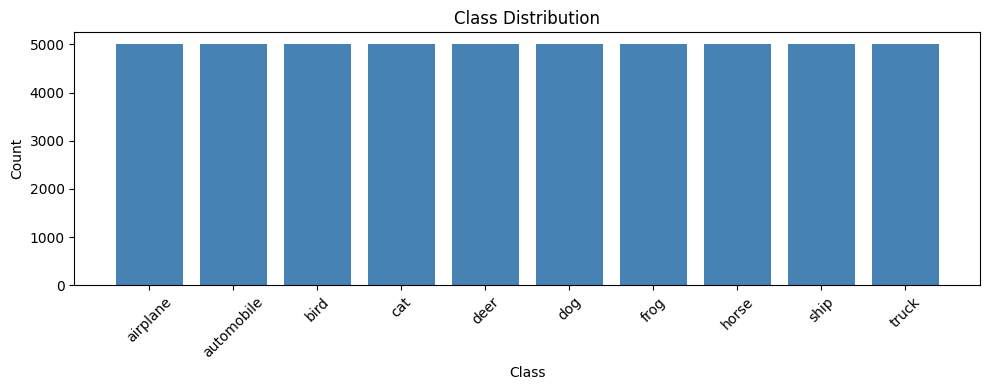

    airplane: 5,000 samples
  automobile: 5,000 samples
        bird: 5,000 samples
         cat: 5,000 samples
        deer: 5,000 samples
         dog: 5,000 samples
        frog: 5,000 samples
       horse: 5,000 samples
        ship: 5,000 samples
       truck: 5,000 samples


In [3]:
import collections

# Count samples per class
labels = [label for _, label in raw_set]
class_counts = collections.Counter(labels)

# Plot
plt.figure(figsize=(10, 4))
plt.bar([CLASSES[i] for i in range(10)], [class_counts[i] for i in range(10)], color='steelblue')
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

for i, cls in enumerate(CLASSES):
    print(f"{cls:>12}: {class_counts[i]:,} samples")

This is a perfectly balanced dataset with 5,000 samples per class. The model won't be biased toward predicting one class more than others just because it saw it more during training. **Accuracy** can be used for a fair evalutaion metric.

#### **2. Sample Images Per Class**

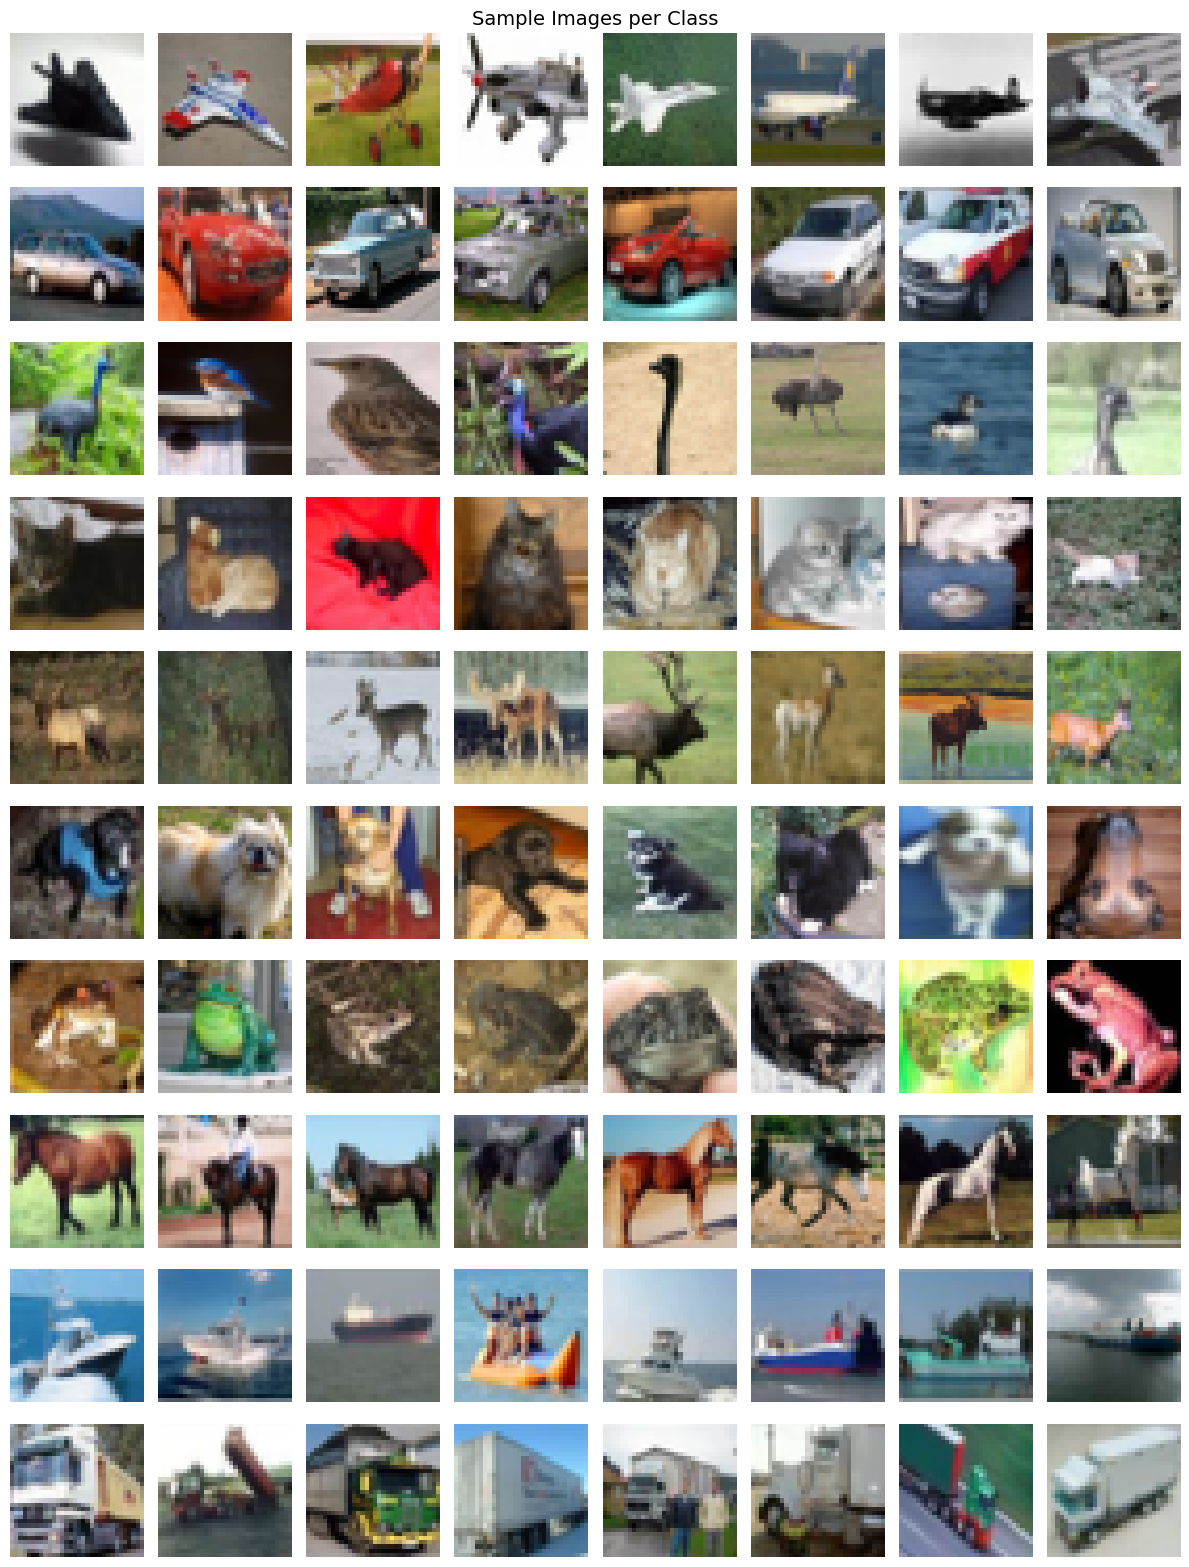

In [4]:
fig, axes = plt.subplots(10, 8, figsize=(12, 16))

for class_idx in range(10):
    # grab first 8 images of each class
    class_images = [img for img, label in raw_set if label == class_idx][:8]
    for col, img in enumerate(class_images):
        ax = axes[class_idx][col]
        ax.imshow(img.permute(1, 2, 0))  # (C,H,W) → (H,W,C)
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(CLASSES[class_idx], fontsize=9, rotation=0,
                         labelpad=40, va='center')

plt.suptitle('Sample Images per Class', fontsize=14)
plt.tight_layout()
plt.show()

#### **3. Pixel Statistics Per Channel**

In [5]:
all_images = torch.stack([img for img, _ in raw_set])  # (50000, 3, 32, 32)

channel_names = ['Red', 'Green', 'Blue']

print("Per-Channel Statistics:")
print(f"{'Channel':<10} {'Mean':>8} {'Std':>8} {'Min':>8} {'Max':>8}")
print("-" * 46)
for i, ch in enumerate(channel_names):
    ch_data = all_images[:, i, :, :]
    print(f"{ch:<10} {ch_data.mean():.4f}   {ch_data.std():.4f}   "
          f"{ch_data.min():.4f}   {ch_data.max():.4f}")

Per-Channel Statistics:
Channel        Mean      Std      Min      Max
----------------------------------------------
Red        0.4914   0.2470   0.0000   1.0000
Green      0.4822   0.2435   0.0000   1.0000
Blue       0.4465   0.2616   0.0000   1.0000


Min and max for all three colors are 0 and 1 respectively. Pixel values are scaled from the original 0-255 range down to 0.0-1.0.

Red is slightly dominant, and Blue is the darkest. This makes sense for natural images.

Standard deviation is around 0.25, which means the images are not too washed out or too extreme.

Per-channel means and stds will be used to normalize inputs before training to stabilize gradient descent.

#### **4. Pixel Value Distribution Per Channel**

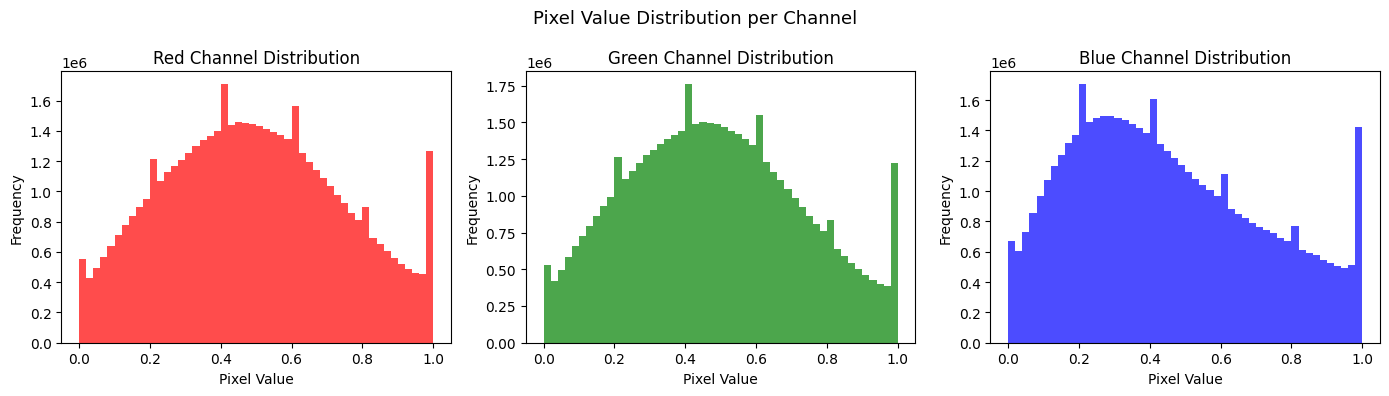

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ['red', 'green', 'blue']

for i, (ch, color) in enumerate(zip(channel_names, colors)):
    axes[i].hist(all_images[:, i, :, :].numpy().flatten(),
                 bins=50, color=color, alpha=0.7)
    axes[i].set_title(f'{ch} Channel Distribution')
    axes[i].set_xlabel('Pixel Value')
    axes[i].set_ylabel('Frequency')

plt.suptitle('Pixel Value Distribution per Channel', fontsize=13)
plt.tight_layout()
plt.show()

All three colors span the full [0,1] range, showing bell-shaped distributions centered near 0.4-0.5 except blue (0.2-0.4). This confirms that normalization with mean and std is appropriate.

### **III. Data Augmentation Pipeline**
For this assignment, three augmentation techniques will be used: **Horizontal Flip, Random Crop, and Color Jitter**.

1. **Horizontal Flip**: Each image has a 50% chance of being mirrored left-to-right during training. Teh class label doesn't change when flipping horizontally, so the model learns that horizontal orientation is irrelavant to classification. We don't want the model to learn "a bird facing right" as a feature.

2. **Random Crop**: In real photos, objects are rearly perfectly centered. This helps the model to learn that position within the image doesn't determine the class. It first pads the 32x32 image witth 4 pixels of blank space on all sides (making it 40x40), then randomly crops a 32x32 region from anywhere that padded image.

3. **Collor Jitter**: Real-world photos are taken under different lightning conditions (sunny, cloudy, indoors, outdoors). This helps the model to learn that exact color values don't define a class. For example, the model can identify a dog under any kind of lightning conditions. So for every image, Color Jitter will randomly adjust brightness, contrast, and saturation.

In [7]:
from torchvision import transforms
from torch.utils.data import random_split, DataLoader

In [8]:
# Training transform with augmentation
train_transform = transforms.Compose([

    # Random Horizontal Flip
    # Randomly flips the image left-right with 50% probability
    transforms.RandomHorizontalFlip(p=0.5),

    # Random Crop
    # Pads the image by 4 pixels on each side, then randomly crops back to 32x32
    transforms.RandomCrop(32, padding=4),

    # Color Jitter
    # Randomly varies brightness, contrast, and saturation
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),

    # Convert to Tensor
    # Converts PIL image → PyTorch tensor and scales pixels from [0,255] → [0.0,1.0]
    transforms.ToTensor(),

    # Normalize
    # Shifts each channel to have mean≈0 and std≈1 using values computed in EDA
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2470, 0.2435, 0.2616]
    ),
])

In [9]:
# Validation/Test Transform no augmentation
val_transform = transforms.Compose([

    # Convert to Tensor only
    transforms.ToTensor(),

    # Normalize with same values as training
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2470, 0.2435, 0.2616]
    ),
])


In [10]:
from torch.utils.data import Subset
# Load dataset TWICE — once per transform
full_train = torchvision.datasets.CIFAR10(root='./data', train=True,
                download=False, transform=train_transform)

full_val   = torchvision.datasets.CIFAR10(root='./data', train=True,
                download=False, transform=val_transform)

# Generate shared indices
indices   = np.random.permutation(len(full_train))
train_idx = indices[:40000]
val_idx   = indices[40000:]

# Each subset points to a different dataset object with different transforms
train_set = Subset(full_train, train_idx)
val_set   = Subset(full_val,   val_idx)

print(f"Training samples   : {len(train_set):,}")
print(f"Validation samples : {len(val_set):,}")


Training samples   : 40,000
Validation samples : 10,000


### **IV. Build The CNN Model**

In [11]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self, num_blocks=3, dropout_rate=0.3):
        super(CNN, self).__init__()

        # Block 1
        # Input: (batch, 3, 32, 32) — 3 RGB channels, 32x32 image
        # Conv layer learns 32 different features from the raw image
        # Kernel 3x3 slides across the image detecting edges, textures
        # Padding=1 keeps spatial dimensions the same after convolution
        self.conv1 = nn.Conv2d(in_channels=3,  out_channels=32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        # MaxPool halves the spatial size: 32x32 → 16x16
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 2
        # Input: (batch, 32, 16, 16)
        # Learns 64 deeper, more complex features from block 1's output
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        # MaxPool: 16x16 → 8x8
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 3
        # Input: (batch, 64, 8, 8)
        # Learns 128 even deeper features — only used if num_blocks=3
        self.num_blocks = num_blocks
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        # MaxPool: 8x8 → 4x4
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Dropout
        # Randomly zeros out neurons during training to prevent overfitting
        # Ex: rate=0.3 means 30% of neurons are dropped each forward pass
        self.dropout = nn.Dropout(p=dropout_rate)

        #  Fully Connected Layers
        # After conv blocks, flatten the feature maps into a 1D vector
        # then classify into 10 classes

        # Input size depends on how many blocks were used:
        # 2 blocks: 64 channels × 8×8 spatial = 4096
        # 3 blocks: 128 channels × 4×4 spatial = 2048
        fc_input_size = 2048 if num_blocks == 3 else 4096

        self.fc1 = nn.Linear(fc_input_size, 256)
        self.fc2 = nn.Linear(256, 10)          # 10 output classes

    def forward(self, x):

        # Block 1
        # Conv → BatchNorm → ReLU → Pool
        # ReLU removes negative values, keeping only positive activations
        # BatchNorm normalizes activations to stabilize training
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))

        # Block 2
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))

        # Block 3
        if self.num_blocks == 3:
            x = self.pool3(F.relu(self.bn3(self.conv3(x))))

        # Flatten
        # Converts 3D feature maps → 1D vector for fully connected layers
        # e.g. (batch, 128, 4, 4) → (batch, 2048)
        x = x.view(x.size(0), -1)

        # Fully Connected
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)   # raw scores (logits) — no softmax needed here
                           # CrossEntropyLoss applies softmax internally

        return x


# Sanity Check
model_2block = CNN(num_blocks=2, dropout_rate=0.3)
model_3block = CNN(num_blocks=3, dropout_rate=0.3)

dummy_input = torch.randn(1, 3, 32, 32)   # 1 fake image

out_2 = model_2block(dummy_input)
out_3 = model_3block(dummy_input)

print(f"2-block output shape : {out_2.shape}")
print(f"3-block output shape : {out_3.shape}")
print(f"\n2-block model:\n{model_2block}")
print(f"\n3-block model:\n{model_3block}")

2-block output shape : torch.Size([1, 10])
3-block output shape : torch.Size([1, 10])

2-block model:
CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=25

### **V. Model Training**

In [12]:
from torch.utils.data import DataLoader
import torch.optim as optim

def train_model(model, train_set, val_set,
                learning_rate=0.001,
                batch_size=128,
                num_epochs=30,
                weight_decay=0):

    # 1. DataLoaders
    # DataLoader feeds data into the model in batches during training
    # shuffle=True for training — randomizes order each epoch so the
    # model doesn't memorize the sequence of images
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)

    # shuffle=False for validation — order doesn't matter, we just
    # want consistent evaluation
    val_loader   = DataLoader(val_set,   batch_size=batch_size, shuffle=False)

    # 2. Device
    # Use GPU if available, otherwise CPU
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model  = model.to(device)
    print(f"Training on: {device}")

    # 3. Loss Function
    # CrossEntropyLoss measures how wrong the model's predictions are
    # It compares the model's 10 output scores against the true label
    # Lower loss = better predictions
    criterion = nn.CrossEntropyLoss()

    # 4. Optimizer
    # Adam adjusts the model's weights after each batch to reduce loss
    # learning_rate controls how big each adjustment step is
    # weight_decay adds L2 regularization if specified (default=0)
    optimizer = optim.Adam(model.parameters(),
                           lr=learning_rate,
                           weight_decay=weight_decay)

    # 5. Tracking
    # Store metrics per epoch so we can plot and compare later
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss':   [], 'val_acc':   []
    }

    # 6. Training Loop
    for epoch in range(num_epochs):

        # Training Phase
        model.train()

        train_loss    = 0.0
        train_correct = 0
        train_total   = 0

        for images, labels in train_loader:

            # Move batch to same device as model
            images, labels = images.to(device), labels.to(device)

            # Step 1: Clear gradients from previous batch
            # If we don't do this, gradients accumulate and corrupt updates
            optimizer.zero_grad()

            # Step 2: Forward pass
            # Feed images through the model, get 10 class scores per image
            outputs = model(images)

            # Step 3: Compute loss
            # Compare predicted scores against true labels
            loss = criterion(outputs, labels)

            # Step 4: Backward pass
            # Compute how much each weight contributed to the loss
            loss.backward()

            # Step 5: Update weights
            # Adjust weights in the direction that reduces loss
            optimizer.step()

            # Track metrics
            train_loss    += loss.item()
            predicted      = outputs.argmax(dim=1)  # class with highest score
            train_correct += (predicted == labels).sum().item()
            train_total   += labels.size(0)

        avg_train_loss = train_loss / len(train_loader)
        avg_train_acc  = train_correct / train_total

        # Validation Phase
        # Tell model we are evaluating
        model.eval()

        val_loss    = 0.0
        val_correct = 0
        val_total   = 0

        # torch.no_grad() disables gradient computation during validation
        # We don't need gradients here — we're just measuring performance
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs        = model(images)
                loss           = criterion(outputs, labels)

                val_loss    += loss.item()
                predicted    = outputs.argmax(dim=1)
                val_correct += (predicted == labels).sum().item()
                val_total   += labels.size(0)

        avg_val_loss = val_loss / len(val_loader)
        avg_val_acc  = val_correct / val_total

        # Store metrics
        history['train_loss'].append(avg_train_loss)
        history['train_acc'].append(avg_train_acc)
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(avg_val_acc)

        # Print progress every epoch
        print(f"Epoch [{epoch+1:02d}/{num_epochs}] "
              f"Train Loss: {avg_train_loss:.4f} | Train Acc: {avg_train_acc:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} | Val Acc: {avg_val_acc:.4f}")

    return model, history

### **VI. Add Early Stopping**
Early stopping monitors the validation loss after each eopch and stops training if it doesn't improve after a ceratain numbe or epochs to prevent the model from overfitting.

In [13]:
 def train_model(model, train_set, val_set,
                learning_rate=0.001,
                batch_size=128,
                num_epochs=30,
                weight_decay=0,
                patience=7):

    # 1. DataLoaders
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_set,   batch_size=batch_size, shuffle=False)

    # 2. Device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model  = model.to(device)
    print(f"Training on: {device}")

    # 3. Loss & Optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(),
                           lr=learning_rate,
                           weight_decay=weight_decay)
    # 4. Tracking
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss':   [], 'val_acc':   []
    }

    # 5. Early Stopping Setup
    # best_val_loss: tracks the lowest validation loss seen so far
    # If current val loss doesn't beat this after 'patience' epochs → stop
    best_val_loss    = float('inf')   # start at infinity so any loss beats it

    # patience_counter: counts how many epochs since last improvement
    # resets to 0 every time we see a new best val loss
    patience_counter = 0

    # Save the best model weights so we can restore them at the end
    # We don't want the final weights, we want the BEST weights
    best_model_state = None

    # 6. Training Loop
    for epoch in range(num_epochs):

        # Training Phase
        model.train()
        train_loss    = 0.0
        train_correct = 0
        train_total   = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss    += loss.item()
            predicted      = outputs.argmax(dim=1)
            train_correct += (predicted == labels).sum().item()
            train_total   += labels.size(0)

        avg_train_loss = train_loss / len(train_loader)
        avg_train_acc  = train_correct / train_total

        # Validation Phase
        model.eval()
        val_loss    = 0.0
        val_correct = 0
        val_total   = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs        = model(images)
                loss           = criterion(outputs, labels)

                val_loss    += loss.item()
                predicted    = outputs.argmax(dim=1)
                val_correct += (predicted == labels).sum().item()
                val_total   += labels.size(0)

        avg_val_loss = val_loss / len(val_loader)
        avg_val_acc  = val_correct / val_total

        # Store metrics
        history['train_loss'].append(avg_train_loss)
        history['train_acc'].append(avg_train_acc)
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(avg_val_acc)

        print(f"Epoch [{epoch+1:02d}/{num_epochs}] "
              f"Train Loss: {avg_train_loss:.4f} | Train Acc: {avg_train_acc:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} | Val Acc: {avg_val_acc:.4f}")

        # 7. Early Stopping Check
        if avg_val_loss < best_val_loss:
            # Val loss improved, reset counter and save model state
            best_val_loss    = avg_val_loss
            patience_counter = 0
            best_model_state = model.state_dict().copy()
            print(f"  ✅ Val loss improved → best model saved")

        else:
            # Val loss did NOT improve — increment counter
            patience_counter += 1
            print(f"No improvement — patience: {patience_counter}/{patience}")

            if patience_counter >= patience:
                # Waited long enough — stop training
                print(f"Early stopping triggered at epoch {epoch+1}")
                break

    # 8. Restore Best Weights
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"Best model weights restored (val loss: {best_val_loss:.4f})")

    return model, history

### **VII. Hyperparameter Experiment Runner**

In [14]:
import copy

BASELINE = {
    'learning_rate' : 0.001,
    'batch_size'    : 128,
    'dropout_rate'  : 0.3,
    'num_blocks'    : 3,
    'weight_decay'  : 0,
    'patience'      : 7,
    'num_epochs'    : 30
}


all_results = {}


# Helper — runs one experiment and stores the result
def run_experiment(exp_name, learning_rate, batch_size, dropout_rate,
                   num_blocks, weight_decay, patience, num_epochs=30):

    print(f"\n{'='*60}")
    print(f"Experiment: {exp_name}")
    print(f"  LR={learning_rate} | Batch={batch_size} | "
          f"Dropout={dropout_rate} | Blocks={num_blocks} | "
          f"L2={weight_decay} | Patience={patience}")
    print(f"{'='*60}")

    # Create a fresh model for each experiment
    # Never reuse a trained model — weights would carry over
    model = CNN(num_blocks=num_blocks, dropout_rate=dropout_rate)

    # Train
    trained_model, history = train_model(
        model          = model,
        train_set      = train_set,
        val_set        = val_set,
        learning_rate  = learning_rate,
        batch_size     = batch_size,
        num_epochs     = num_epochs,
        weight_decay   = weight_decay,
        patience       = patience
    )

    # Store best validation accuracy achieved
    best_val_acc = max(history['val_acc'])
    all_results[exp_name] = {
        'val_acc'  : best_val_acc,
        'history'  : history,
        'config'   : {
            'learning_rate' : learning_rate,
            'batch_size'    : batch_size,
            'dropout_rate'  : dropout_rate,
            'num_blocks'    : num_blocks,
            'weight_decay'  : weight_decay,
            'patience'      : patience
        }
    }

    print(f"\n✅ {exp_name} → Best Val Acc: {best_val_acc:.4f}")
    return trained_model, history


# Experiment 1 — Learning Rates
# Varying: 0.01, 0.001, 0.0001
# Fixed: everything else at baseline

print("\n" + "🔬 EXPERIMENT 1: LEARNING RATES " + "="*28)

trained_lr1, history_lr1 = run_experiment(
    exp_name      = 'LR=0.01',
    learning_rate = 0.01,
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = BASELINE['patience']
)

trained_lr2, history_lr2 = run_experiment(
    exp_name      = 'LR=0.001',
    learning_rate = 0.001,
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = BASELINE['patience']
)

trained_lr3, history_lr3 = run_experiment(
    exp_name      = 'LR=0.0001',
    learning_rate = 0.0001,
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = BASELINE['patience']
)

# Experiment 2 — Batch Sizes
# Varying: 32, 128, 512
# Fixed: everything else at baseline

print("\n" + "🔬 EXPERIMENT 2: BATCH SIZES " + "="*31)

trained_bs1, history_bs1 = run_experiment(
    exp_name      = 'Batch=32',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = 32,
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = BASELINE['patience']
)

trained_bs2, history_bs2 = run_experiment(
    exp_name      = 'Batch=128',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = 128,
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = BASELINE['patience']
)

trained_bs3, history_bs3 = run_experiment(
    exp_name      = 'Batch=512',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = 512,
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = BASELINE['patience']
)


# Experiment 3 — Dropout Rates
# Varying: 0.0, 0.3, 0.6
# Fixed: everything else at baseline

print("\n" + "🔬 EXPERIMENT 3: DROPOUT RATES " + "="*29)

trained_dr1, history_dr1 = run_experiment(
    exp_name      = 'Dropout=0.0',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = 0.0,
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = BASELINE['patience']
)

trained_dr2, history_dr2 = run_experiment(
    exp_name      = 'Dropout=0.3',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = 0.3,
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = BASELINE['patience']
)

trained_dr3, history_dr3 = run_experiment(
    exp_name      = 'Dropout=0.6',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = 0.6,
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = BASELINE['patience']
)

# Experiment 4 — Network Depth
# Varying: 2 blocks, 3 blocks, 3 blocks + L2
# Fixed: everything else at baseline

print("\n" + "🔬 EXPERIMENT 4: NETWORK DEPTH " + "="*29)

trained_nd1, history_nd1 = run_experiment(
    exp_name      = 'Blocks=2',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = 2,
    weight_decay  = 0,
    patience      = BASELINE['patience']
)

trained_nd2, history_nd2 = run_experiment(
    exp_name      = 'Blocks=3',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = 3,
    weight_decay  = 0,
    patience      = BASELINE['patience']
)

trained_nd3, history_nd3 = run_experiment(
    exp_name      = 'Blocks=3+L2',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = 3,
    weight_decay  = 1e-4,      # L2 regularization
    patience      = BASELINE['patience']
)

# Experiment 5 — Early Stopping Patience
# Varying: 3, 7, 15
# Fixed: everything else at baseline

print("\n" + "🔬 EXPERIMENT 5: EARLY STOPPING PATIENCE " + "="*19)

trained_es1, history_es1 = run_experiment(
    exp_name      = 'Patience=3',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = 3
)

trained_es2, history_es2 = run_experiment(
    exp_name      = 'Patience=7',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = 7
)

trained_es3, history_es3 = run_experiment(
    exp_name      = 'Patience=15',
    learning_rate = BASELINE['learning_rate'],
    batch_size    = BASELINE['batch_size'],
    dropout_rate  = BASELINE['dropout_rate'],
    num_blocks    = BASELINE['num_blocks'],
    weight_decay  = BASELINE['weight_decay'],
    patience      = 15
)


# Summary

print("📊 ALL EXPERIMENT RESULTS — Ranked by Val Accuracy")


sorted_results = sorted(all_results.items(),
                        key=lambda x: x[1]['val_acc'],
                        reverse=True)

for rank, (name, result) in enumerate(sorted_results, 1):
    print(f"{rank:>2}. {name:<20} Val Acc: {result['val_acc']:.4f}")


🔬 EXPERIMENT 1: LEARNING RATES ============================

Experiment: LR=0.01
  LR=0.01 | Batch=128 | Dropout=0.3 | Blocks=3 | L2=0 | Patience=7
Training on: cuda
Epoch [01/30] Train Loss: 2.4307 | Train Acc: 0.1601 | Val Loss: 2.0063 | Val Acc: 0.1960
  ✅ Val loss improved → best model saved
Epoch [02/30] Train Loss: 2.0200 | Train Acc: 0.1966 | Val Loss: 1.8711 | Val Acc: 0.2325
  ✅ Val loss improved → best model saved
Epoch [03/30] Train Loss: 1.9129 | Train Acc: 0.2602 | Val Loss: 1.8132 | Val Acc: 0.2882
  ✅ Val loss improved → best model saved
Epoch [04/30] Train Loss: 1.8245 | Train Acc: 0.2957 | Val Loss: 1.6098 | Val Acc: 0.3925
  ✅ Val loss improved → best model saved
Epoch [05/30] Train Loss: 1.7487 | Train Acc: 0.3354 | Val Loss: 1.4456 | Val Acc: 0.4880
  ✅ Val loss improved → best model saved
Epoch [06/30] Train Loss: 1.5668 | Train Acc: 0.4095 | Val Loss: 1.3337 | Val Acc: 0.5047
  ✅ Val loss improved → best model saved
Epoch [07/30] Train Loss: 1.4269 | Train Acc: 0

#### **Write-up**
**1. Learning Rate**
- LR=0.001 achieved the best validation accuracy of 0.8192.
- LR=0.01 performed worst despite being the largest. The steps were too large causing the optimizer to overshoot the optimal weights and never properly converge.
- LR=0.0001 was too small, meaning the model made very tiny adjustments each step and couldn't converge sufficiently within 30 epochs.
- LR=0.001 strikes the right balance. It is large enough to learn efficiently, small enough to converge stably.

**2. Batch Size**
- Batch=128 performed best at 0.8216, closely followed by Batch=32 at 0.8203.
- Batch=512 performed noticeably worse at 0.7940. - Small batches (32) introduce more noise into gradient updates which can help escape local minima but slows training.
- Large batches (512) produce very smooth gradient estimates but this actually hurts generalization. The model finds sharp minima that don't transfer well to unseen data.
- Batch=128 balances both, getting stable enough gradients while maintaining enough noise for good generalization.

**3. Dropout Rate**
- Dropout=0.3 achieved the best validation accuracy of 0.8184.
- No dropout (0.0) performed slightly worse at 0.8149, suggesting the model was beginning to overfit, memorizing training patterns rather than learning generalizable features.
- Dropout=0.6 performed worst at 0.7884 because dropping 60% of neurons removes too much information during each forward pass, making it very difficult for the model to learn meaningful patterns at all.
- Dropout=0.3 provides the right level of regularization. It is enough to prevent memorization without crippling the learning capacity.

**4. Network Depth**
- 3 conv blocks significantly outperformed 2 blocks (0.8165 vs 0.7648).
- The 2-block model lacked the depth to learn complex enough features from CIFAR-10 images. It could detect basic edges and textures but couldn't combine them into higher-level object representations.
- Adding L2 weight decay (1e-4) to the 3-block model made no difference. Both achieved identical accuracy of 0.8165. This suggests the model was not significantly overfitting, so L2 regularization had nothing meaningful to correct.
- The main takeaway is that depth matters more than regularization for this dataset.


**5. Early Stopping Patience**
- Patience=15 achieved the best validation accuracy of 0.8225.
- Patience=3 stopped training too early. The model hadn't fully converged yet and was stopped prematurely before it could reach its best performance.
- Patience=7 gave more room but still stopped before the model reached its peak.
- Patience=15 allowed the model enough time to keep improving through temporary plateaus in validation loss, ultimately finding a better solution.
- This shows that for CIFAR-10, validation loss can temporarily stall before improving again, so a higher patience value is more appropriate.

**Final Conclusions**
The best single experiment was Patience=15, however the optimal overall configuration combining all best individual settings would be: LR=0.001, Batch=128, Dropout=0.3, 3 conv blocks, Patience=15. These settings together balance learning speed, generalization, model capacity, and training duration to produce the strongest classifier.